In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Crop Yield Analysis & Prediction")
print("Environment ready!")

Crop Yield Analysis & Prediction
Environment ready!


In [2]:
import pandas as pd
from pathlib import Path

# Locate the dataset
DATA_PATH = Path("../data/crop_yield.csv")

# Load the dataset
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (19689, 10)


In [3]:
# Display the first 5 rows
df.head()

,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,2051.4,7024878.38,22882.34,0.796087
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,2051.4,631643.29,2057.47,0.710435
2,Castor seed,1997,Kharif,Assam,796.0,22,2051.4,75755.32,246.76,0.238333
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,2051.4,1870661.52,6093.36,5238.051739
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,2051.4,165500.63,539.09,0.420909


In [4]:
# Check column names and data types
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 19689 entries, 0 to 19688
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Crop             19689 non-null  str    
 1   Crop_Year        19689 non-null  int64  
 2   Season           19689 non-null  str    
 3   State            19689 non-null  str    
 4   Area             19689 non-null  float64
 5   Production       19689 non-null  int64  
 6   Annual_Rainfall  19689 non-null  float64
 7   Fertilizer       19689 non-null  float64
 8   Pesticide        19689 non-null  float64
 9   Yield            19689 non-null  float64
dtypes: float64(5), int64(2), str(3)
memory usage: 1.5 MB


In [5]:
# Generate summary statistics for numerical columns
df.describe()

,Crop_Year,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
count,19689.000000,1.968900e+04,1.968900e+04,19689.000000,1.968900e+04,1.968900e+04,19689.000000
mean,2009.127584,1.799266e+05,1.643594e+07,1437.755177,2.410331e+07,4.884835e+04,79.954009
std,6.498099,7.328287e+05,2.630568e+08,816.909589,9.494600e+07,2.132874e+05,878.306193
min,1997.000000,5.000000e-01,0.000000e+00,301.300000,5.417000e+01,9.000000e-02,0.000000
25%,2004.000000,1.390000e+03,1.393000e+03,940.700000,1.880146e+05,3.567000e+02,0.600000
50%,2010.000000,9.317000e+03,1.380400e+04,1247.600000,1.234957e+06,2.421900e+03,1.030000
75%,2015.000000,7.511200e+04,1.227180e+05,1643.700000,1.000385e+07,2.004170e+04,2.388889
max,2020.000000,5.080810e+07,6.326000e+09,6552.700000,4.835407e+09,1.575051e+07,21105.000000


In [6]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
Crop               0
Crop_Year          0
Season             0
State              0
Area               0
Production         0
Annual_Rainfall    0
Fertilizer         0
Pesticide          0
Yield              0
dtype: int64

Duplicate rows: 0


In [7]:
print("Unique crops:", df["Crop"].nunique())
print("Unique seasons:", df["Season"].nunique())
print("Unique states:", df["State"].nunique())

print("\nCrop names:")
print(sorted(df["Crop"].str.strip().unique()))

print("\nSeason names:")
print(sorted(df["Season"].str.strip().unique()))

Unique crops: 55
Unique seasons: 6
Unique states: 30

Crop names:
['Arecanut', 'Arhar/Tur', 'Bajra', 'Banana', 'Barley', 'Black pepper', 'Cardamom', 'Cashewnut', 'Castor seed', 'Coconut', 'Coriander', 'Cotton(lint)', 'Cowpea(Lobia)', 'Dry chillies', 'Garlic', 'Ginger', 'Gram', 'Groundnut', 'Guar seed', 'Horse-gram', 'Jowar', 'Jute', 'Khesari', 'Linseed', 'Maize', 'Masoor', 'Mesta', 'Moong(Green Gram)', 'Moth', 'Niger seed', 'Oilseeds total', 'Onion', 'Other  Rabi pulses', 'Other Cereals', 'Other Kharif pulses', 'Other Summer Pulses', 'Peas & beans (Pulses)', 'Potato', 'Ragi', 'Rapeseed &Mustard', 'Rice', 'Safflower', 'Sannhamp', 'Sesamum', 'Small millets', 'Soyabean', 'Sugarcane', 'Sunflower', 'Sweet potato', 'Tapioca', 'Tobacco', 'Turmeric', 'Urad', 'Wheat', 'other oilseeds']

Season names:
['Autumn', 'Kharif', 'Rabi', 'Summer', 'Whole Year', 'Winter']


In [8]:
print("Yield distribution:")
print(df["Yield"].describe(percentiles=[0.90, 0.95, 0.99]))

print("\nTop 10 highest-yield records:")
print(
    df.nlargest(10, "Yield")[
        ["Crop", "Crop_Year", "Season", "State",
         "Area", "Production", "Yield"]
    ].to_string(index=False)
)

Yield distribution:
count    19689.000000
mean        79.954009
std        878.306193
min          0.000000
90%          9.532000
95%         21.914857
99%        104.273387
max      21105.000000
Name: Yield, dtype: float64

Top 10 highest-yield records:
    Crop  Crop_Year      Season          State     Area  Production       Yield
Coconut        2014 Whole Year       Telangana    439.0     9265095 21105.00000
Coconut        2019 Whole Year  Andhra Pradesh 104027.0  1912224000 16935.05846
Coconut        2013 Whole Year       Telangana    428.0     6956712 16254.00000
Coconut        2018 Whole Year  Andhra Pradesh 104530.0  1571100000 15636.63231
Coconut        2012 Whole Year  Andhra Pradesh  99825.0  1670659000 14794.63000
Coconut        2012 Whole Year      Puducherry   1564.0    20297000 14410.51667
Coconut        2009 Whole Year      Tamil Nadu 400466.0  5547100000 14134.65935
Coconut        2016 Whole Year  Andhra Pradesh 102548.0  1415300000 13934.12250
Coconut        2008 Whole

In [9]:
df["Calculated_Yield"] = df["Production"] / df["Area"]

print(
    df[["Production", "Area", "Yield", "Calculated_Yield"]]
    .head(10)
)

   Production     Area        Yield  Calculated_Yield
0       56708  73814.0     0.796087          0.768255
1        4685   6637.0     0.710435          0.705891
2          22    796.0     0.238333          0.027638
3   126905000  19656.0  5238.051739       6456.298331
4         794   1739.0     0.420909          0.456584
5        9073  13587.0     0.643636          0.667771
6        1507   2979.0     0.465455          0.505874
7      904095  94520.0     9.919565          9.565118
8        5158  10098.0     0.461364          0.510794
9       14721  19216.0     0.615652          0.766080


In [10]:
# Compare yield statistics across crops
crop_yield_stats = (
    df.groupby("Crop")["Yield"]
    .agg(["count", "mean", "median", "min", "max"])
    .sort_values("median", ascending=False)
)

crop_yield_stats.head(15)

,count,mean,median,min,max
Crop,,,,,
Coconut,172,8652.000199,8466.315523,0.000000,21105.000000
Sugarcane,605,51.727439,53.158158,0.290000,165.000000
Banana,245,26.851128,17.948750,0.000000,126.387692
Tapioca,201,16.667301,11.117778,0.000000,42.097857
Potato,628,13.331718,10.175284,0.000000,311.020000
Onion,454,13.247525,9.192846,0.000000,381.420000
Sweet potato,273,9.240788,8.512727,0.000000,26.339444
Jute,181,7.555393,8.146250,0.000000,25.430556
Mesta,210,5.389204,4.935250,0.000000,17.678750


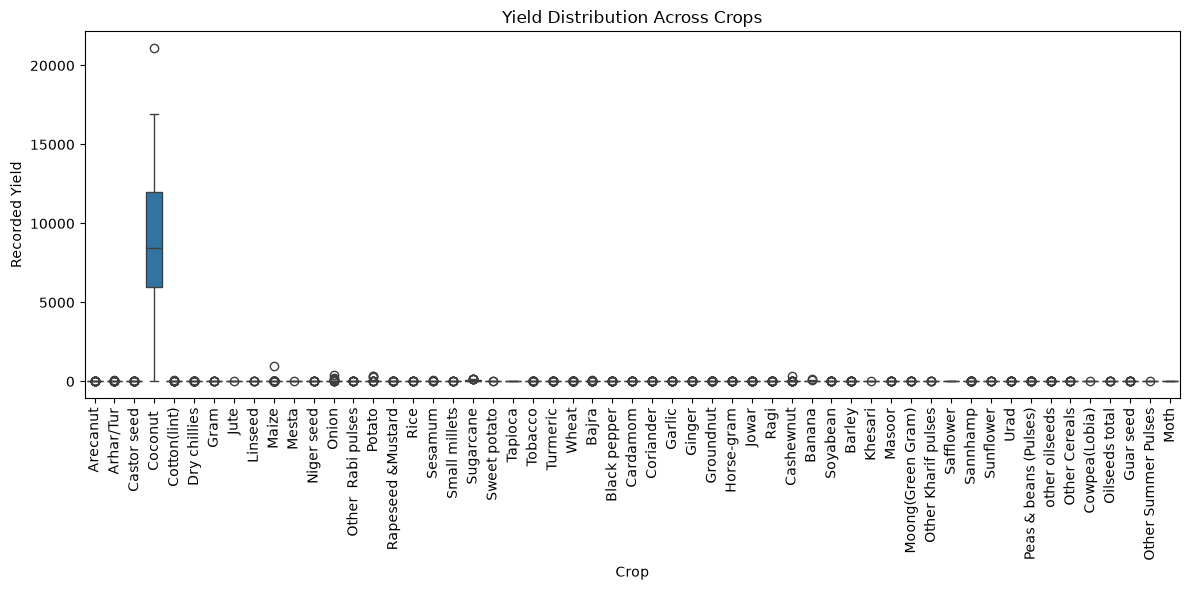

In [11]:
# Compare the distribution of yield values
plt.figure(figsize=(12, 6))

sns.boxplot(data=df, x="Crop", y="Yield")

plt.xticks(rotation=90)
plt.title("Yield Distribution Across Crops")
plt.xlabel("Crop")
plt.ylabel("Recorded Yield")
plt.tight_layout()
plt.show()

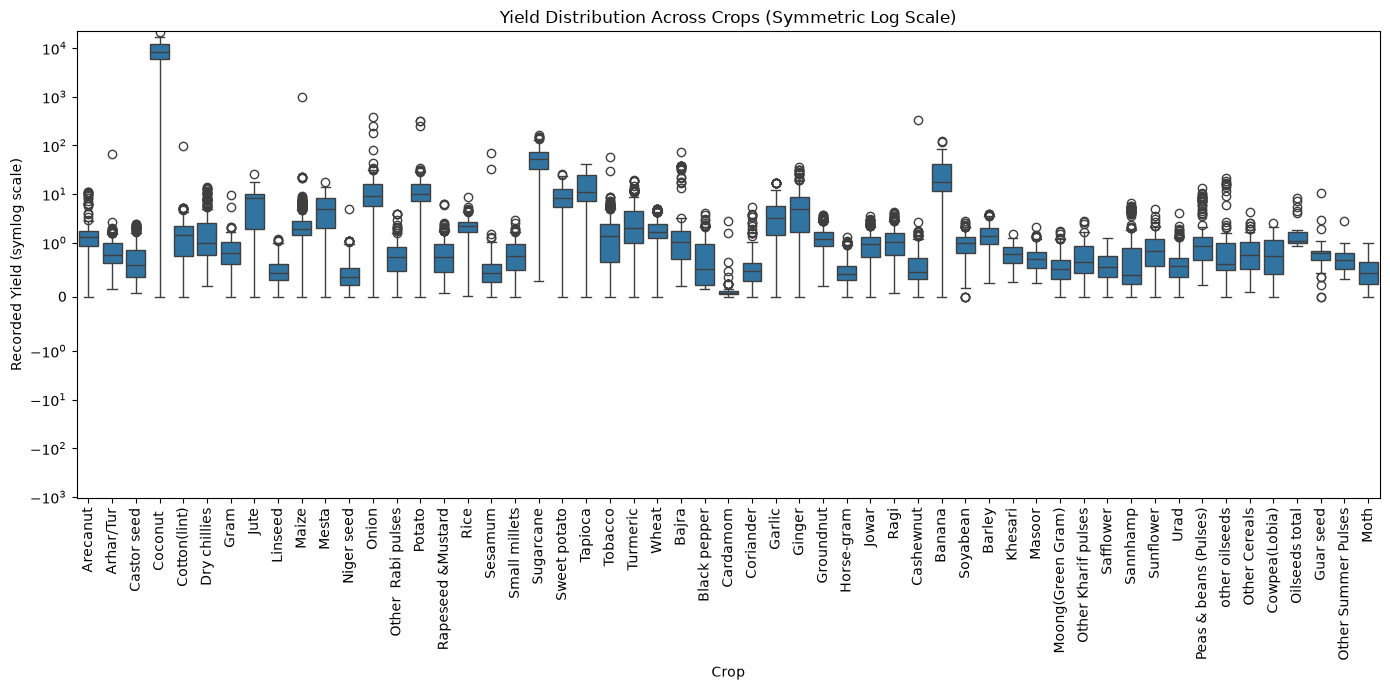

In [12]:
plt.figure(figsize=(14, 7))

sns.boxplot(data=df, x="Crop", y="Yield")

plt.yscale("symlog", linthresh=1)
plt.xticks(rotation=90)
plt.title("Yield Distribution Across Crops (Symmetric Log Scale)")
plt.xlabel("Crop")
plt.ylabel("Recorded Yield (symlog scale)")
plt.tight_layout()
plt.show()

In [13]:
crop_stats = (
    df.groupby("Crop")["Yield"]
    .agg(["count", "median", "mean", "max"])
    .sort_values("median", ascending=False)
)

display(crop_stats.head(15))

,count,median,mean,max
Crop,,,,
Coconut,172,8466.315523,8652.000199,21105.000000
Sugarcane,605,53.158158,51.727439,165.000000
Banana,245,17.948750,26.851128,126.387692
Tapioca,201,11.117778,16.667301,42.097857
Potato,628,10.175284,13.331718,311.020000
Onion,454,9.192846,13.247525,381.420000
Sweet potato,273,8.512727,9.240788,26.339444
Jute,181,8.146250,7.555393,25.430556
Mesta,210,4.935250,5.389204,17.678750


In [14]:
# Inspect all Coconut records
coconut = df[df["Crop"].str.strip() == "Coconut"].copy()

coconut["Calculated_Yield"] = (
    coconut["Production"] / coconut["Area"]
)

display(
    coconut[
        ["Crop_Year", "State", "Area", "Production",
         "Yield", "Calculated_Yield"]
    ].sort_values("Yield", ascending=False).head(15)
)

,Crop_Year,State,Area,Production,Yield,Calculated_Yield
13962,2014,Telangana,439.0,9265095,21105.00000,21105.000000
5771,2019,Andhra Pradesh,104027.0,1912224000,16935.05846,18381.996982
13406,2013,Telangana,428.0,6956712,16254.00000,16254.000000
5425,2018,Andhra Pradesh,104530.0,1571100000,15636.63231,15030.134890
3610,2012,Andhra Pradesh,99825.0,1670659000,14794.63000,16735.877786
18015,2012,Puducherry,1564.0,20297000,14410.51667,12977.621483
3052,2009,Tamil Nadu,400466.0,5547100000,14134.65935,13851.612871
4742,2016,Andhra Pradesh,102548.0,1415300000,13934.12250,13801.341811
2724,2008,Tamil Nadu,389429.0,5362000000,13834.07258,13768.876997
3836,2013,Andhra Pradesh,99066.0,1610007000,13712.57308,16251.862395


In [15]:
# Check how recorded yield relates to production / area
coconut["Yield_Ratio"] = (
    coconut["Yield"] / coconut["Calculated_Yield"].replace(0, np.nan)
)

print(coconut["Yield_Ratio"].describe())

count    165.000000
mean       0.957972
std        0.080034
min        0.764966
25%        0.912530
50%        0.956451
75%        1.000000
max        1.432445
Name: Yield_Ratio, dtype: float64


In [16]:
# Calculate yield directly from production and area
df["Calculated_Yield"] = df["Production"] / df["Area"]

# Compare recorded yield with calculated yield
df["Yield_Ratio"] = (
    df["Yield"] / df["Calculated_Yield"].replace(0, np.nan)
)

print("Usable ratios:", df["Yield_Ratio"].notna().sum())
print("\nRatio summary:")
print(df["Yield_Ratio"].describe())

print("\nRatio summary by crop:")
display(
    df.groupby("Crop")["Yield_Ratio"]
    .agg(["count", "median", "min", "max"])
    .sort_values("median")
)

Usable ratios: 19577

Ratio summary:
count    19577.000000
mean         1.044495
std          4.660522
min          0.000000
25%          0.937475
50%          0.996333
75%          1.034553
max        649.800140
Name: Yield_Ratio, dtype: float64

Ratio summary by crop:


,count,median,min,max
Crop,,,,
Cardamom,74,0.858696,0.000000,8.480240
Khesari,75,0.954783,0.584312,1.307620
Coconut,165,0.956451,0.764966,1.432445
Rapeseed &Mustard,528,0.964060,0.343662,2.585495
Rice,1197,0.973991,0.317694,5.044683
Sugarcane,605,0.981284,0.376289,4.888797
Maize,974,0.984067,0.232754,6.420000
Arecanut,160,0.984771,0.450075,3.182667
Wheat,543,0.986653,0.510000,1.566379


In [17]:
# Find records where recorded yield differs most
# from production divided by area

df["Absolute_Ratio_Difference"] = (
    df["Yield_Ratio"] - 1
).abs()

display(
    df.nlargest(15, "Absolute_Ratio_Difference")[
        [
            "Crop",
            "Crop_Year",
            "Season",
            "State",
            "Area",
            "Production",
            "Yield",
            "Calculated_Yield",
            "Yield_Ratio",
        ]
    ]
)

,Crop,Crop_Year,Season,State,Area,Production,Yield,Calculated_Yield,Yield_Ratio
2722,Cashewnut,2008,Whole Year,Tamil Nadu,99168.0,51667,338.548966,0.521005,649.800140
11336,Arhar/Tur,2009,Winter,Jharkhand,441.0,764,68.230000,1.732426,39.384071
13102,Niger seed,2013,Kharif,Chhattisgarh,63611.0,11567,4.987647,0.181840,27.428825
14862,Sunflower,2016,Kharif,Chhattisgarh,2273.0,7,0.054706,0.003080,17.763781
9721,Sunflower,2006,Kharif,Chhattisgarh,6493.0,2724,5.020000,0.419529,11.965808
10659,Onion,2008,Whole Year,Haryana,2492.0,37400,178.653077,15.008026,11.903836
7458,Turmeric,2000,Whole Year,Uttarakhand,152.0,39,2.778000,0.256579,10.827077
5104,Onion,2017,Kharif,Andhra Pradesh,17336.0,662728,381.420000,38.228426,9.977392
3444,other oilseeds,2011,Rabi,Andhra Pradesh,6967.0,4422,5.857500,0.634706,9.228675
15479,Sunflower,2017,Kharif,Chhattisgarh,1265.0,7,0.050667,0.005534,9.156191


In [18]:
# Compare recorded yield with production / area
# Exclude rows where the calculated yield is zero

valid = df["Calculated_Yield"] > 0

ratio = (
    df.loc[valid, "Yield"]
    / df.loc[valid, "Calculated_Yield"]
)

# Percentage difference from the calculated yield
difference_pct = (ratio - 1).abs() * 100

print("Records with a calculable yield:", len(ratio))
print()

for threshold in [10, 25, 50, 100]:
    count = (difference_pct > threshold).sum()
    percentage = count / len(ratio) * 100

    print(
        f"Difference greater than {threshold}%: "
        f"{count} records ({percentage:.2f}%)"
    )

Records with a calculable yield: 19577

Difference greater than 10%: 6175 records (31.54%)
Difference greater than 25%: 1987 records (10.15%)
Difference greater than 50%: 493 records (2.52%)
Difference greater than 100%: 128 records (0.65%)


In [19]:
# Check the distribution of crop records
print(df["Crop"].value_counts().head(15))

# Check how many records exist per year
print(df["Crop_Year"].value_counts().sort_index())

# Check the number of records per season
print(df["Season"].str.strip().value_counts())

Crop
Rice                 1197
Maize                 975
Moong(Green Gram)     740
Urad                  733
Groundnut             725
Sesamum               685
Potato                628
Sugarcane             605
Wheat                 545
Rapeseed &Mustard     528
Bajra                 524
Jowar                 513
Arhar/Tur             508
Ragi                  498
Gram                  490
Name: count, dtype: int64
Crop_Year
1997     410
1998     646
1999     650
2000     772
2001     750
2002     815
2003     801
2004     787
2005     811
2006     823
2007     828
2008     847
2009     865
2010     859
2011     907
2012     894
2013     976
2014     965
2015     998
2016    1036
2017    1070
2018    1063
2019    1079
2020      37
Name: count, dtype: int64
Season
Kharif        8232
Rabi          5742
Whole Year    3717
Summer        1195
Autumn         414
Winter         389
Name: count, dtype: int64


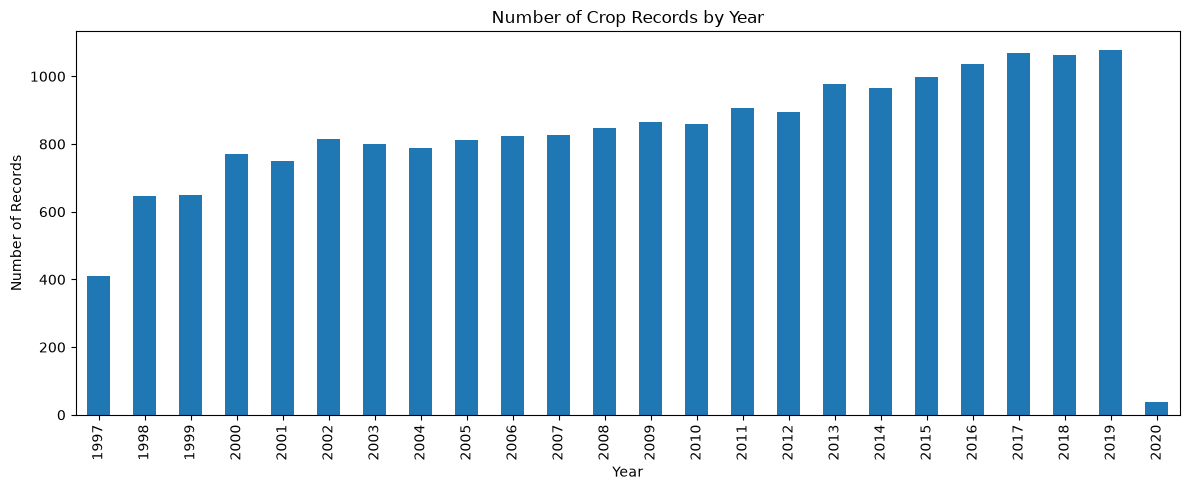

In [20]:
# Count records per year
year_counts = df["Crop_Year"].value_counts().sort_index()

plt.figure(figsize=(12, 5))
year_counts.plot(kind="bar")

plt.title("Number of Crop Records by Year")
plt.xlabel("Year")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

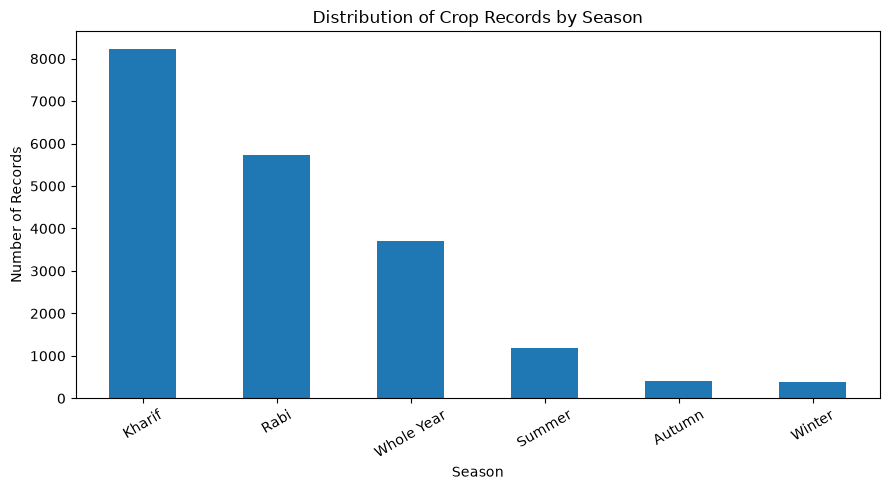

In [21]:
# Count records per season
season_counts = df["Season"].str.strip().value_counts()

plt.figure(figsize=(9, 5))
season_counts.plot(kind="bar")

plt.title("Distribution of Crop Records by Season")
plt.xlabel("Season")
plt.ylabel("Number of Records")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [22]:
# Clean whitespace in season labels for analysis
df["Season_Clean"] = df["Season"].str.strip()

# Calculate yield statistics by season
season_yield = (
    df.groupby("Season_Clean")["Yield"]
    .agg(["count", "median", "mean"])
    .sort_values("median", ascending=False)
)

display(season_yield)

,count,median,mean
Season_Clean,,,
Whole Year,3717,4.295122,412.995463
Summer,1195,1.673750,2.997370
Winter,389,1.545333,5.287267
Autumn,414,1.091677,3.917482
Kharif,8232,0.924226,2.482002
Rabi,5742,0.902660,1.988518


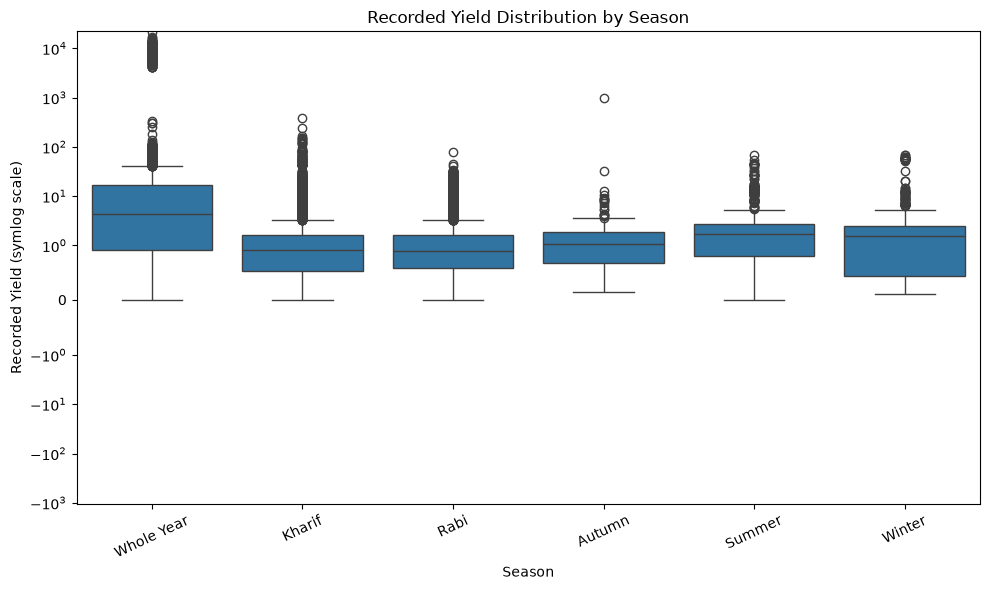

In [23]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Season_Clean",
    y="Yield"
)

plt.yscale("symlog", linthresh=1)
plt.title("Recorded Yield Distribution by Season")
plt.xlabel("Season")
plt.ylabel("Recorded Yield (symlog scale)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [24]:
# Inspect crop composition within each season
season_crop_counts = pd.crosstab(
    df["Season_Clean"],
    df["Crop"].str.strip()
)

# Show the most represented crops in Whole Year
whole_year_crops = (
    df[df["Season_Clean"] == "Whole Year"]
    ["Crop"]
    .str.strip()
    .value_counts()
)

display(whole_year_crops.head(15))

Crop
Sugarcane       507
Potato          272
Turmeric        259
Tobacco         252
Dry chillies    226
Banana          197
Garlic          193
Onion           191
Sweet potato    185
Coconut         170
Ginger          142
Coriander       138
Arecanut        126
Tapioca         117
Black pepper    107
Name: count, dtype: int64

In [25]:
# Compare median yield by crop within Whole Year
whole_year_stats = (
    df[df["Season_Clean"] == "Whole Year"]
    .assign(Crop=lambda data: data["Crop"].str.strip())
    .groupby("Crop")["Yield"]
    .agg(["count", "median", "mean", "max"])
    .sort_values("median", ascending=False)
)

display(whole_year_stats.head(10))

,count,median,mean,max
Crop,,,,
Coconut,170,8492.035338,8753.773172,21105.000000
Sugarcane,507,52.287733,50.543816,136.075185
Bajra,25,33.112857,26.635740,74.303077
Banana,197,17.680370,26.770727,126.387692
Potato,272,10.282833,15.895174,311.020000
Tapioca,117,9.647778,17.332037,42.097857
Onion,191,8.546250,11.315927,178.653077
Sweet potato,185,7.320000,9.200161,26.339444
Ginger,142,5.792611,7.649063,36.357826


In [26]:
whole_year = df[df["Season_Clean"] == "Whole Year"].copy()
whole_year["Crop"] = whole_year["Crop"].str.strip()

whole_year_summary = (
    whole_year.groupby("Crop")["Yield"]
    .agg(["count", "median", "mean", "max"])
    .sort_values("median", ascending=False)
)

display(whole_year_summary.head(15))

,count,median,mean,max
Crop,,,,
Coconut,170,8492.035338,8753.773172,21105.000000
Sugarcane,507,52.287733,50.543816,136.075185
Bajra,25,33.112857,26.635740,74.303077
Banana,197,17.680370,26.770727,126.387692
Potato,272,10.282833,15.895174,311.020000
Tapioca,117,9.647778,17.332037,42.097857
Onion,191,8.546250,11.315927,178.653077
Sweet potato,185,7.320000,9.200161,26.339444
Ginger,142,5.792611,7.649063,36.357826


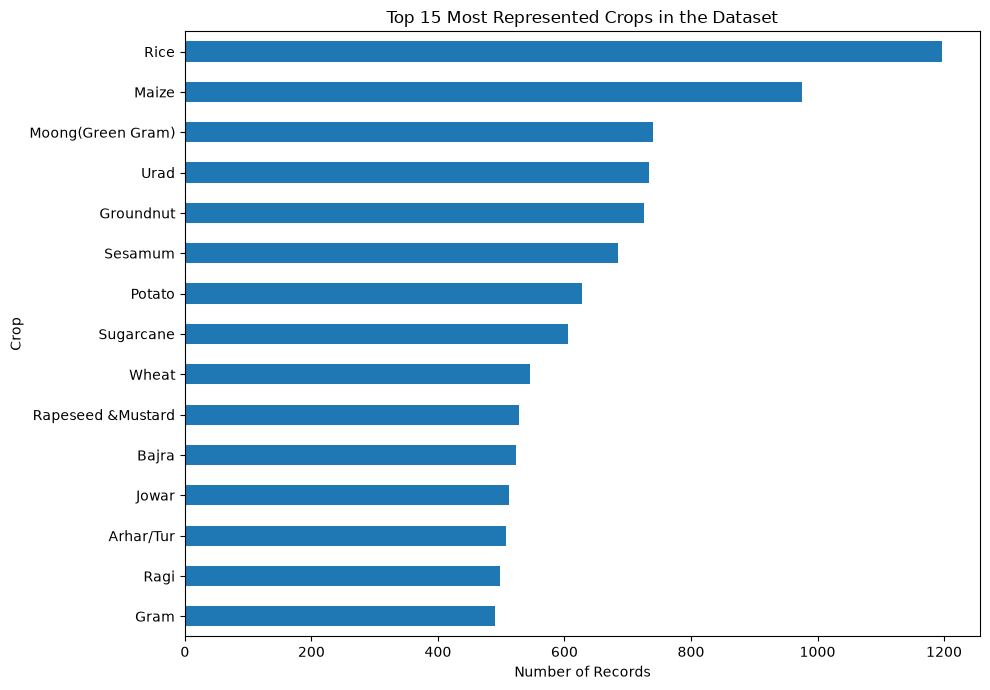

In [27]:
# Top 15 crops by number of records
crop_counts = (
    df["Crop"]
    .str.strip()
    .value_counts()
    .head(15)
    .sort_values()
)

plt.figure(figsize=(10, 7))

crop_counts.plot(kind="barh")

plt.title("Top 15 Most Represented Crops in the Dataset")
plt.xlabel("Number of Records")
plt.ylabel("Crop")
plt.tight_layout()
plt.show()

In [ ]:
## Initial Data Exploration — Findings

### Dataset Overview
- 19,689 records and 10 columns.
- Covers crop records from 1997 to 2020.
- Includes crop, season, state, area, production, rainfall, fertilizer, pesticide, and yield.

### Initial Observations
- Rice is the most represented crop, with 1,197 records.
- Kharif is the most represented season, with 8,232 records.
- The number of records varies by year; 2020 contains only 37 records.
- Recorded yield is strongly right-skewed, with substantial differences between crops.
- Some recorded yield values differ substantially from Production divided by Area.

### Limitations and Next Steps
- Verify the definition and units of yield before final model development.
- Investigate data inconsistencies without automatically deleting outliers.
- Avoid feature leakage when selecting model inputs.
- Continue with focused exploratory analysis and machine learning after validation.